# Численное дифференцирование

Построить графики абсолютной погрешности каждого метода в зависимости от шага численного дифференцирования $h_n = \dfrac{2}{2^n}$, $n = \overline{1,21}$, для функций

$$\sin(x^2),\quad \cos(\sin x),\quad \exp(\sin(\cos x)),\quad \ln(x+3),\quad (x+3)^{0.5}.$$

Масштаб по обеим осям логарифмический, графики для каждой функции строятся отдельно. Погрешность вычисляется относительно аналитической производной.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## Параметры

Точка $x_0 = 0.5$ выбрана так, чтобы:
- $x_0 > 0$: формула 5 при $h_1 = 1$ вычисляет $f(x_0 - 3)$, а $\ln(x+3)$ и $(x+3)^{0.5}$ определены только при $x > -3$;
- $x_0$ и все узлы $x_0 \pm k h_n$ были двоичными дробями: тогда они точно представимы в double и не вносят своей погрешности.

In [ ]:
X0 = 0.5                # точка дифференцирования
N = np.arange(1, 22)    
H = 2.0 / 2.0**N        # шаги h_n = 2 / 2^n: от 1 до 2^-20 ≈ 9.5e-7

## Функции и их аналитические производные

$$
\begin{aligned}
(\sin x^2)' &= 2x\cos x^2,\\
(\cos(\sin x))' &= -\sin(\sin x)\,\cos x,\\
\bigl(e^{\sin(\cos x)}\bigr)' &= -\,e^{\sin(\cos x)}\cos(\cos x)\,\sin x,\\
(\ln(x+3))' &= \frac{1}{x+3},\\
\bigl((x+3)^{0.5}\bigr)' &= \frac{1}{2\sqrt{x+3}}.
\end{aligned}
$$

In [ ]:
FUNCTIONS = [
    (r"\sin(x^2)", "sin_x2",
     lambda x: np.sin(x**2),
     lambda x: 2 * x * np.cos(x**2)),
    (r"\cos(\sin x)", "cos_sin",
     lambda x: np.cos(np.sin(x)),
     lambda x: -np.sin(np.sin(x)) * np.cos(x)),
    (r"\exp(\sin(\cos x))", "exp_sin_cos",
     lambda x: np.exp(np.sin(np.cos(x))),
     lambda x: -np.exp(np.sin(np.cos(x))) * np.cos(np.cos(x)) * np.sin(x)),
    (r"\ln(x+3)", "ln",
     lambda x: np.log(x + 3),
     lambda x: 1 / (x + 3)),
    (r"(x+3)^{0.5}", "sqrt",
     lambda x: (x + 3)**0.5,
     lambda x: 0.5 * (x + 3)**(-0.5)),
]

## Формулы численного дифференцирования

1. $\dfrac{f(x+h)-f(x)}{h}$, порядок $O(h)$
2. $\dfrac{f(x)-f(x-h)}{h}$, порядок $O(h)$
3. $\dfrac{f(x+h)-f(x-h)}{2h}$, порядок $O(h^2)$
4. $\dfrac{4}{3}\,\dfrac{f(x+h)-f(x-h)}{2h}-\dfrac{1}{3}\,\dfrac{f(x+2h)-f(x-2h)}{4h}$, порядок $O(h^4)$
5. $\dfrac{3}{2}\,\dfrac{f(x+h)-f(x-h)}{2h}-\dfrac{3}{5}\,\dfrac{f(x+2h)-f(x-2h)}{4h}+\dfrac{1}{10}\,\dfrac{f(x+3h)-f(x-3h)}{6h}$, порядок $O(h^6)$

In [ ]:
def central(f, x, h):
    """Центральная разность (f(x+h) - f(x-h)) / 2h."""
    return (f(x + h) - f(x - h)) / (2 * h)

def method1(f, x, h):
    return (f(x + h) - f(x)) / h


def method2(f, x, h):
    return (f(x) - f(x - h)) / h


def method3(f, x, h):
    return central(f, x, h)


def method4(f, x, h):
    return 4/3 * central(f, x, h) - 1/3 * central(f, x, 2 * h)


def method5(f, x, h):
    return (3/2 * central(f, x, h)
            - 3/5 * central(f, x, 2 * h)
            + 1/10 * central(f, x, 3 * h))

METHODS = [
    (r"1:  $O(h)$",   method1),
    (r"2:  $O(h)$",   method2),
    (r"3:  $O(h^2)$", method3),
    (r"4:  $O(h^4)$", method4),
    (r"5:  $O(h^6)$", method5),
]

## Погрешность и графики

Абсолютная погрешность формулы: $\Delta(h) = \bigl|D(h) - f'(x_0)\bigr|$, где $D(h)$ — значение производной по формуле численного дифференцирования. Каждый график также сохраняется в PNG рядом с ноутбуком.

In [ ]:
STYLES = [
    dict(color="#2a78d6", marker="o", ms=5, ls="-",  mec="white", mew=0.6),
    dict(color="#eb6834", marker="s", ms=8, ls="--", mfc="none",  mew=1.2),
    dict(color="#1baf7a", marker="^", ms=6, ls="-",  mec="white", mew=0.6),
    dict(color="#eda100", marker="D", ms=5, ls="-",  mec="white", mew=0.6),
    dict(color="#e87ba4", marker="v", ms=6, ls="-",  mec="white", mew=0.6),
]

plt.rcParams.update({
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def abs_errors(f, df, method):
    """Абсолютная погрешность |D(h) - f'(X0)| для всех шагов H."""
    err = np.abs(method(f, X0, H) - df(X0))
    err[err == 0] = np.nan
    return err


def plot_function(idx):
    """График погрешностей всех пяти формул для функции номер idx (1..5)."""
    tex, slug, f, df = FUNCTIONS[idx - 1]
    fig, ax = plt.subplots(num=f"f{idx}: {slug}", figsize=(8, 5.5), clear=True)
    for (label, method), style in zip(METHODS, STYLES):
        ax.loglog(H, abs_errors(f, df, method), label=label, lw=1.5, **style)
    ax.set_title(rf"$f(x) = {tex}$,   $x_0 = {X0}$")
    ax.set_xlabel(r"шаг $h$")
    ax.set_ylabel(r"абсолютная погрешность $|D(h) - f'(x_0)|$")
    ax.grid(True, which="major", color="#e1e0d9", lw=0.8)
    ax.legend(title="формула, порядок", loc="upper left")
    fig.tight_layout()
    fig.savefig(f"error_f{idx}_{slug}.png", dpi=150)

### 1. $f(x) = \sin(x^2)$

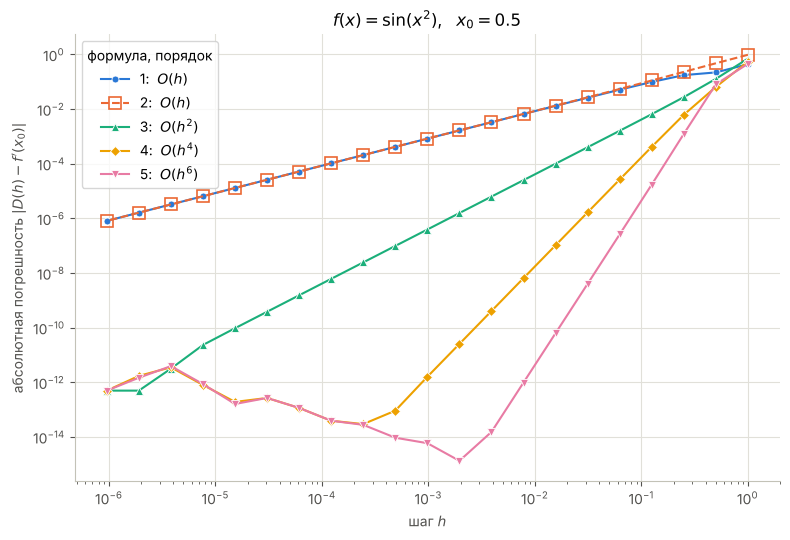

In [6]:
plot_function(1)

### 2. $f(x) = \cos(\sin x)$

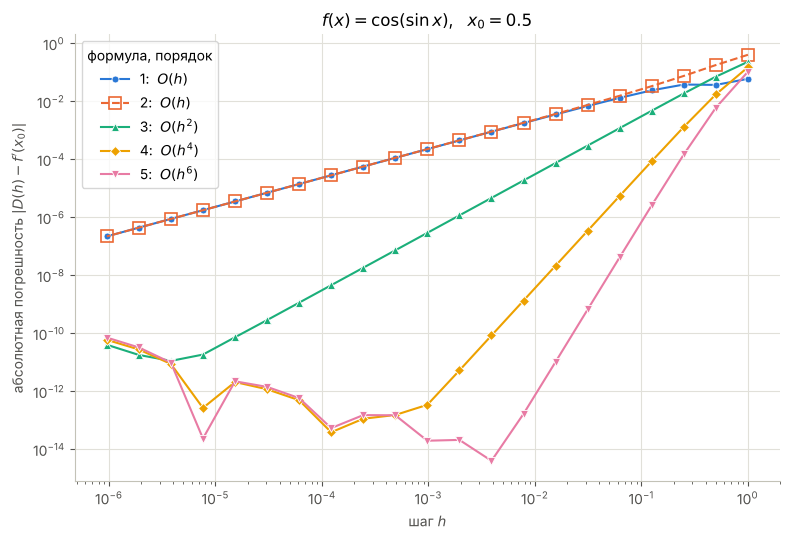

In [7]:
plot_function(2)

### 3. $f(x) = \exp(\sin(\cos x))$

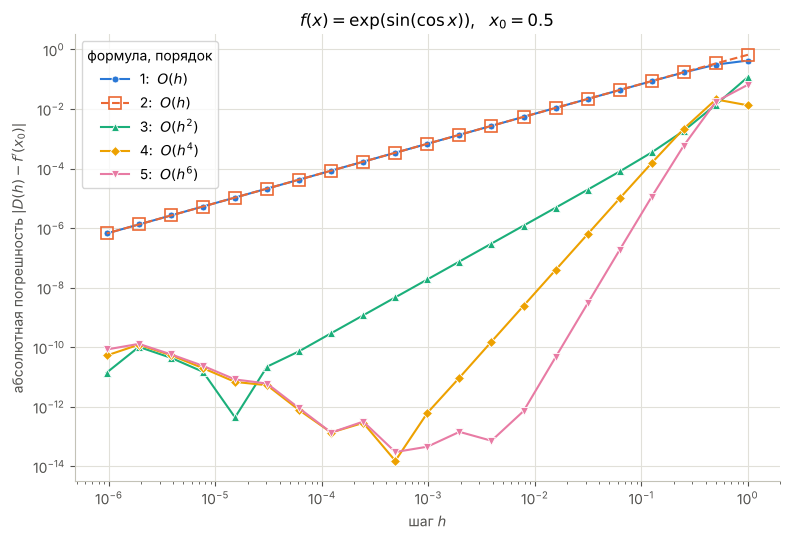

In [8]:
plot_function(3)

### 4. $f(x) = \ln(x+3)$

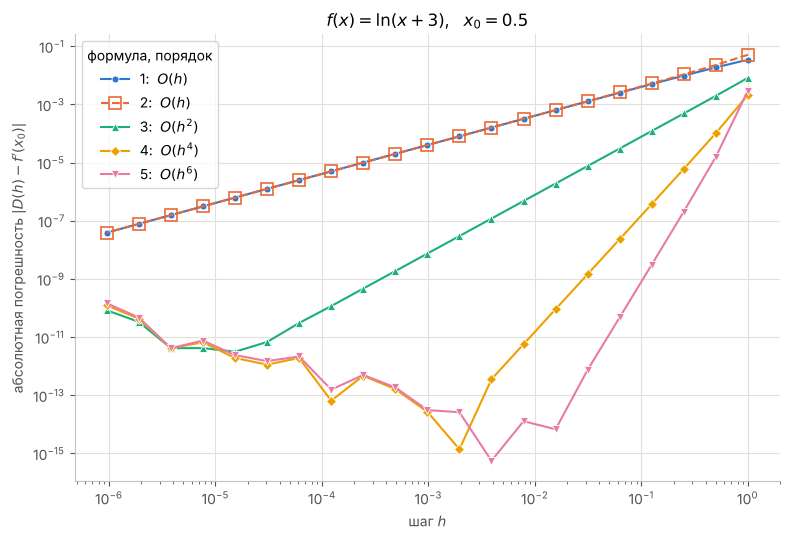

In [9]:
plot_function(4)

### 5. $f(x) = (x+3)^{0.5}$

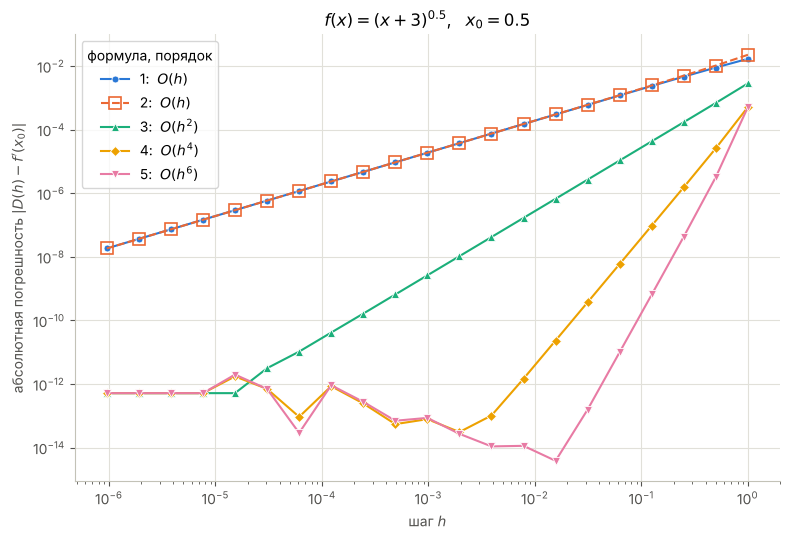

In [10]:
plot_function(5)